In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Environment ready!")
print("Scikit-learn version:", sklearn.__version__)


Environment ready!
Scikit-learn version: 1.9.1


Generating Synthetic Dataset:
Trying to use this relationship: \[
y = \sin(1.5\pi x) + \epsilon
\]

In [13]:
import numpy as np

rng=np.random.default_rng(42)
# print(rng)
# rng

X=rng.uniform(0,1,120)
X= np.sort(X)
# print(X)

X=X.reshape(120,1)
# print(X)

y_true = np.sin(1.5 * np.pi * X.ravel())
noise=rng.normal(0, 0.25, 120)
y=y_true + noise

print("Input shape:", X.shape)
print("True output shape:", y_true.shape)
print("Observed target shape:", y.shape)

# Display a few observations to verify the data
print("\nFirst five input values:")
print(X[:5])

print("\nFirst five true outputs:")
print(y_true[:5])

print("\nFirst five noisy targets:")
print(y[:5])


Input shape: (120, 1)
True output shape: (120,)
Observed target shape: (120,)

First five input values:
[[0.00736227]
 [0.02271207]
 [0.03081783]
 [0.04380377]
 [0.05830274]]

First five true outputs:
[0.03468692 0.10682391 0.14471568 0.2049576  0.2713017 ]

First five noisy targets:
[ 0.43513164  0.046985   -0.11115869  0.2497765   0.32630087]


Visualizing the dataset

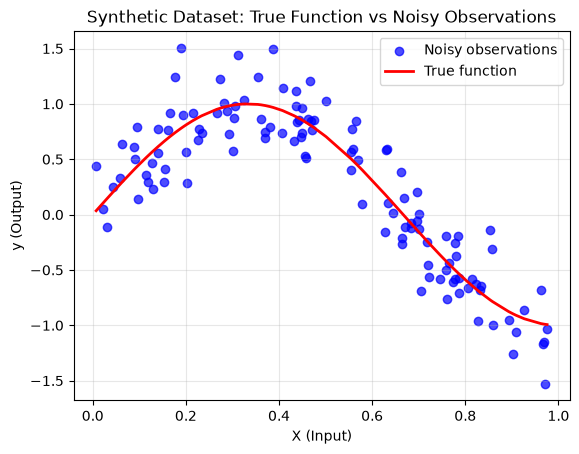

In [15]:
plt.Figure(figsize=(10, 6))
# plotting the noise observations as individual points
plt.scatter(X.ravel(), y, color='blue', label='Noisy observations',alpha=0.7)
# plotting the true function as a curve
plt.plot(X.ravel(), y_true, color='red', label='True function', linewidth=2)


plt.xlabel("X (Input)")
plt.ylabel("y (Output)")

# Add a title to the graph
plt.title("Synthetic Dataset: True Function vs Noisy Observations")

# Display the legend
plt.legend()

# Add a grid to make the graph easier to read
plt.grid(alpha=0.3)

# Render the plot
plt.show()

Train, validation and test split

In [16]:
from sklearn.model_selection import train_test_split
# diving dataset into training n remaining (validation + test) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, random_state=42)
# remaining (validation + test) set is divided into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print("\nTraining set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])



Training set size: 72
Validation set size: 24
Test set size: 24


Building a baseline linear regression model

In [17]:
from sklearn.linear_model import LinearRegression
baseline_model = LinearRegression()

baseline_model.fit(X_train, y_train)

y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

Evaluate the model

In [18]:
from sklearn.metrics import mean_squared_error
train_mse = mean_squared_error(y_train, y_train_pred)
val_mse = mean_squared_error(y_val, y_val_pred)

train_rmse = np.sqrt(train_mse)
val_rmse = np.sqrt(val_mse)

print("\nTraining RMSE:", train_rmse)
print("Validation RMSE:", val_rmse) 


Training RMSE: 0.48775804791033034
Validation RMSE: 0.48417301310724076


Visualizing the baseline

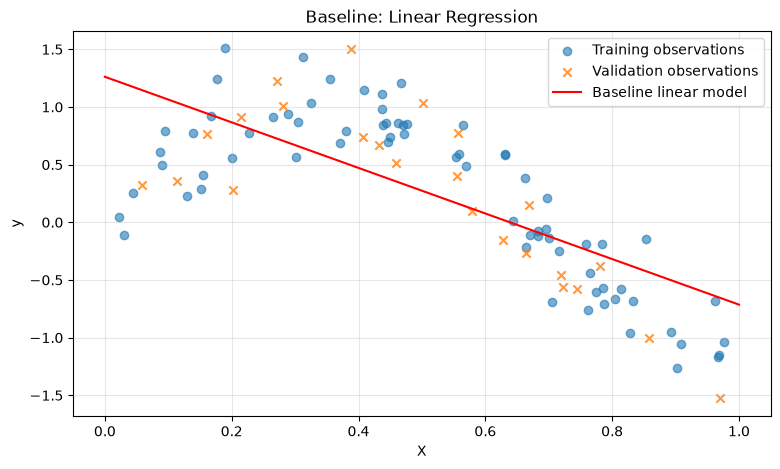

In [19]:
# import matplotlib.pyplot as plt
# GPT generated code to visualize the baseline linear regression model's predictions against the training and validation data
plt.figure(figsize=(9, 5))

plt.scatter(X_train.ravel(), y_train, alpha=0.6, label="Training observations")
plt.scatter(X_val.ravel(), y_val, alpha=0.8, marker="x", label="Validation observations")

# Sort inputs so the line is drawn smoothly
X_plot = np.linspace(0, 1, 200).reshape(-1, 1)
y_plot = baseline_model.predict(X_plot)

plt.plot(X_plot.ravel(), y_plot, color="red", label="Baseline linear model")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Baseline: Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

training and evaluation 6 models of varying degrees [1, 2, 3, 5, 10, 15];

In [22]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
degrees = [1, 2, 3, 5, 10, 15]
results = []
for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree=degree,include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

    results.append({
        "degree": degree,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

   degree  train_rmse  val_rmse
0       1      0.4878    0.4842
1       2      0.3015    0.3313
2       3      0.2536    0.2918
3       5      0.2471    0.3000
4      10      0.2438    0.3045
5      15      0.2400    0.3057


Plotting the error

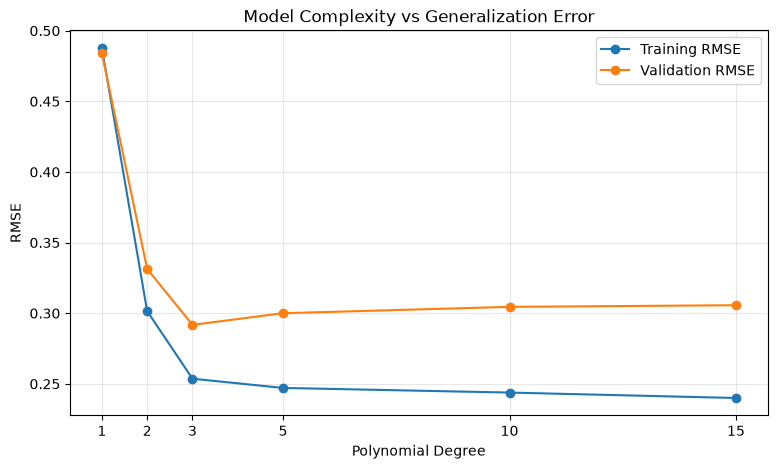

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["degree"],
    results_df["train_rmse"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    results_df["degree"],
    results_df["val_rmse"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Model Complexity vs Generalization Error")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Plotting the fitted curves

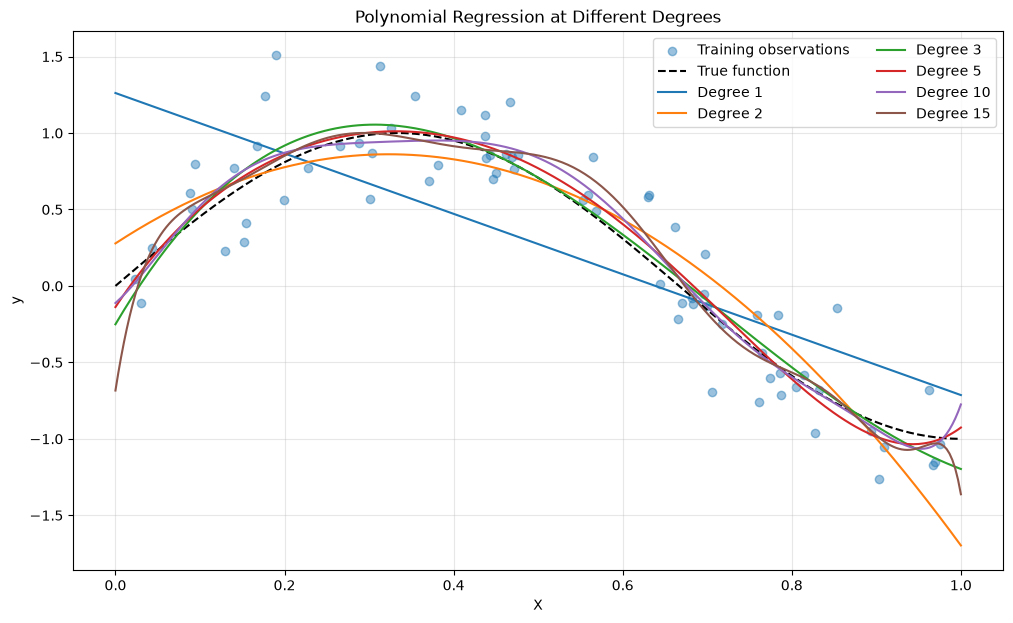

In [27]:
X_plot = np.linspace(0, 1, 300).reshape(-1, 1)

plt.figure(figsize=(12, 7))

plt.scatter(X_train.ravel(), y_train, alpha=0.45, label="Training observations")
plt.plot(X_plot.ravel(), np.sin(1.5 * np.pi * X_plot.ravel()),
         color="black", linestyle="--", label="True function")

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    y_plot = model.predict(X_plot)

    plt.plot(X_plot.ravel(), y_plot, label=f"Degree {degree}")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Polynomial Regression at Different Degrees")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.show()

Ridge Regression: Effect of Regularization

In [28]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

degree = 10
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_results = []
ridge_models = {}

for alpha in alphas:
    # Build the polynomial Ridge regression pipeline
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    # Fit using training data only
    model.fit(X_train, y_train)

    # Generate predictions
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    # Calculate RMSE
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

    ridge_results.append({
        "Alpha": alpha,
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

    ridge_models[alpha] = model

ridge_df = pd.DataFrame(ridge_results)
print(ridge_df.round(4))

     Alpha  Training RMSE  Validation RMSE
0    0.001         0.2470           0.2945
1    0.010         0.2477           0.2944
2    0.100         0.2513           0.3047
3    1.000         0.2724           0.3257
4   10.000         0.3414           0.3648
5  100.000         0.4033           0.4243


Visualizing effect of regularization

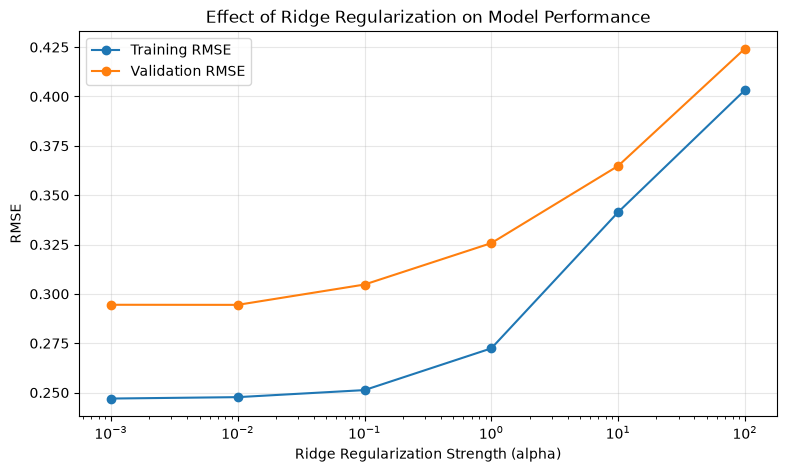

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    ridge_df["Alpha"],
    ridge_df["Training RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    ridge_df["Alpha"],
    ridge_df["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xscale("log")
plt.xlabel("Ridge Regularization Strength (alpha)")
plt.ylabel("RMSE")
plt.title("Effect of Ridge Regularization on Model Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Best alpha tested: 0.01.

Stronger regularization increased both training and validation RMSE in this experiment.

The best Ridge result did not outperform degree-3 polynomial regression on the current validation split.

A single split is insufficient to establish that these differences will persist on other samples.

Effect of training set size

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

fractions = [0.2, 0.4, 0.6, 0.8, 1.0]

learning_results = []

for fraction in fractions:
    # Determine how many training observations to use
    n_samples = int(len(X_train) * fraction)

    X_subset = X_train[:n_samples]
    y_subset = y_train[:n_samples]

    # Build and train the model
    model = make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_subset, y_subset)

    # Evaluate on the subset used for training
    train_pred = model.predict(X_subset)
    train_rmse = np.sqrt(mean_squared_error(y_subset, train_pred))

    # Evaluate on the same, unchanged validation set
    val_pred = model.predict(X_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    learning_results.append({
        "Training Samples": n_samples,
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

learning_df = pd.DataFrame(learning_results)
print(learning_df.round(4))

   Training Samples  Training RMSE  Validation RMSE
0                14         0.1676           0.3999
1                28         0.2226           0.2997
2                43         0.2267           0.2837
3                57         0.2457           0.2829
4                72         0.2536           0.2918


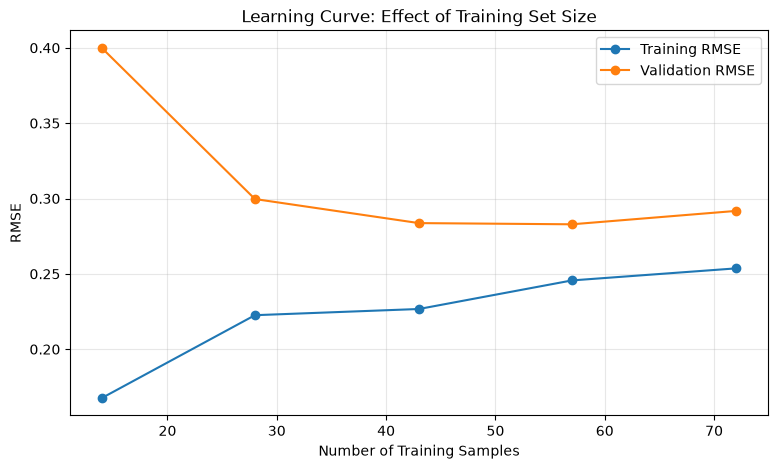

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    learning_df["Training Samples"],
    learning_df["Training RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    learning_df["Training Samples"],
    learning_df["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")
plt.title("Learning Curve: Effect of Training Set Size")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Increasing training-set size substantially reduced validation RMSE initially. Performance then stabilized, with a small increase at the largest sample size. Given the small validation set and single sequence of subsets, this fluctuation should be treated as sampling variability rather than evidence that additional data reduces generalization.

FINAL TEST SET EVALUATION::

In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

final_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"Final test RMSE: {test_rmse:.4f}")

Final test RMSE: 0.2558


In [33]:
baseline_test_pred = baseline_model.predict(X_test)

baseline_test_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_test_pred)
)

print(f"Baseline test RMSE: {baseline_test_rmse:.4f}")
print(f"Degree-3 test RMSE: {test_rmse:.4f}")

improvement = (
    (baseline_test_rmse - test_rmse) / baseline_test_rmse
) * 100

print(f"Relative RMSE improvement: {improvement:.2f}%")

Baseline test RMSE: 0.4015
Degree-3 test RMSE: 0.2558
Relative RMSE improvement: 36.30%


## Conclusion

This experiment investigated the effects of polynomial model complexity, Ridge regularization, and training-set size on regression generalization using a synthetic dataset generated from a noisy sine function.

The linear regression baseline achieved a validation RMSE of 0.4842. Increasing polynomial degree substantially improved performance, with degree 3 achieving the lowest validation RMSE of 0.2918. Higher-degree models continued to reduce training error but showed slightly worse validation performance, suggesting that additional complexity was not improving generalization.

The Ridge regression experiment showed that stronger regularization increased both training and validation error over most of the tested range. The training-set-size experiment showed that validation error decreased substantially as more training observations were added initially, although small fluctuations remained.

Finally, the selected degree-3 model achieved a test RMSE of 0.2558, compared with 0.4015 for the linear baseline, representing a 36.30% reduction in test RMSE.

These results demonstrate the importance of validation-based model selection and independent test evaluation. However, the small dataset and single train-validation-test split limit the strength of the conclusions. Repeated experiments with different random seeds and a real-world dataset would help assess the robustness of these findings.